<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Lucas Barbosa Simão

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://)

LINK PARA SEU VÍDEO NO YOUTUBE: [Aqui](https://)

<center>

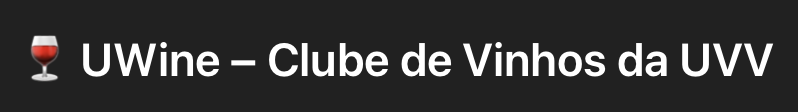

<center>

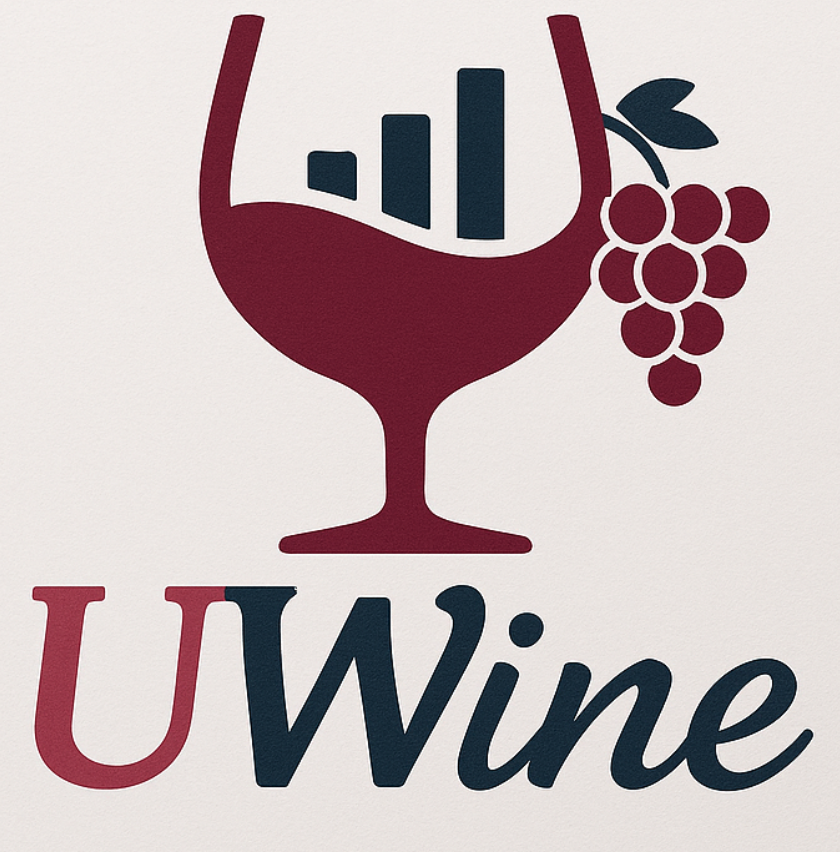

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import json
import scipy.stats as stats

import statsmodels.api as sm
import scipy.stats as stats
from scipy.stats import bootstrap
from sklearn.datasets import fetch_california_housing

# Example of the Normality Test
from scipy.stats import anderson
from scipy.stats import shapiro
from scipy.stats import normaltest

# Example of the Correlation Tests
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import kendalltau
from scipy.stats import chi2_contingency

# Parametric Statistical Hypothesis Tests

# Example of the Student's t-test
from scipy.stats import ttest_ind
# Example of the Paired Student's t-test
from scipy.stats import ttest_rel
# Example of the Analysis of Variance Test: ANOVA
from scipy.stats import f_oneway

# Nonparametric Statistical Hypothesis Tests

# Example of the Mann-Whitney U Test
from scipy.stats import mannwhitneyu
# Example of the Wilcoxon Signed-Rank Test
from scipy.stats import wilcoxon
# Example of the Kruskal-Wallis H Test
from scipy.stats import kruskal
# Example of the Friedman Test
from scipy.stats import friedmanchisquare

# Example of the Augmented Dickey-Fuller unit root test
from statsmodels.tsa.stattools import adfuller

import seaborn as sns


In [ ]:
# load do seu TABLE aqui: Numero 39
table39 = pd.read_csv('table39.csv', index_col=0)

In [ ]:
display(table39.head())

n_linhas, n_colunas = table39.shape
print(f"Dimensão da base: {n_linhas:,} linhas e {n_colunas} colunas.")

table39.info()

valores_nulos = table39.isna().sum().sort_values(ascending=False)
valores_nulos = valores_nulos[valores_nulos > 0]

if len(valores_nulos) > 0:
    display(valores_nulos)
else:
    print("Não foram identificados valores ausentes na base de dados.")

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,2133464,SUDESTE,MASCULINO,SOLTEIRO,1,20934.69,"Serviço eficiente, recomendo o clube: UVVine",68.68,12.112362,2.364343,...,1.568322,-1.105657,0.305339,1.505564,7.412056,0.899557,3.600344,230.321000,PRIME,3351.54
1,2132654,SUL,FEMININO,CASADO,0,15222.06,Gostei do atendimento prestado pela UVVine,68.68,13.496391,0.981209,...,2.635974,0.891965,0.357728,1.456450,5.969997,1.078526,3.499191,597.065682,VIP,763.09
2,1636809,SUDESTE,MASCULINO,SOLTEIRO,1,3138.69,"Produto perfeito, chegou antes do prazo de pre...",68.68,12.692379,1.980748,...,2.685325,0.509754,0.441584,1.213032,5.720257,0.801030,2.768711,994.572696,ESSENTIAL,504.18
3,7747450,SUL,MASCULINO,SOLTEIRO,1,3145.85,Nada digno de nota com a UVVine,68.68,13.560746,1.535440,...,1.600321,1.867420,0.371640,1.512026,6.452460,0.896366,3.096530,559.799346,ESSENTIAL,159.28
4,5598044,SUDESTE,MASCULINO,CASADO,0,3251.55,Funcionou bem e me atendeu no prazo certo a UV...,68.68,14.371924,3.363914,...,2.485618,0.169018,0.408146,1.226684,3.509668,1.167548,1.975544,583.288435,ESSENTIAL,424.69


Dimensão da base: 1,120,000 linhas e 23 colunas.
<class 'pandas.core.frame.DataFrame'>
Index: 1120000 entries, 0 to 1119999
Data columns (total 23 columns):
 #   Column                              Non-Null Count    Dtype  
---  ------                              --------------    -----  
 0   NOTA FISCAL                         1120000 non-null  int64  
 1   REGIÃO                              1120000 non-null  object 
 2   SEXO                                1120000 non-null  object 
 3   ESTADO CIVIL                        1120000 non-null  object 
 4   DEPENDENTES                         1120000 non-null  int64  
 5   RENDA BRUTO (R$)                    1120000 non-null  float64
 6   OPINIÃO DO CLIENTE                  1120000 non-null  object 
 7   NOTA DE SATISFAÇÃO (%)              1120000 non-null  float64
 8   MEAN: alcohol                       1120000 non-null  float64
 9   MEAN: malic_acid                    1120000 non-null  float64
 10  MEAN: ash                         

In [ ]:
table39.shape

(1120000, 23)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1.inset_locator import (
    inset_axes,
    mark_inset
)


def optimal_sample_size(
    df,
    value_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the operational sample size for an infinite population
    using consecutive marginal stabilization of the standard error.

    Stabilization is confirmed when the marginal reduction in the
    projected standard error is less than or equal to the specified
    threshold for a given number of consecutive sample-size increments.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the reference or pilot data.

    value_column : str
        Name of the numerical variable used to estimate variability.

    n_min : int, default=100
        Minimum candidate sample size.

    n_max : int, default=50000
        Maximum candidate sample size.

    step : int, default=100
        Increment between candidate sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum acceptable marginal reduction in the standard error.
        For a monetary variable, 0.01 represents R$ 0.01.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions required to confirm
        stabilization.

    plot : bool, default=True
        If True, displays the standard-error curve, the mean
        standard-error line and a zoom window around the stabilization
        sequence.

    Returns
    -------
    dict
        Dictionary containing:

        - optimal_sample_size:
          Sample size at which stabilization is confirmed.

        - stabilization_start:
          First sample size in the confirmed sequence.

        - standard_error:
          Standard error at the recommended sample size.

        - mean_standard_error:
          Mean of the projected standard errors.

        - marginal_reduction:
          Marginal reduction at the confirmation point.

        - population_standard_deviation:
          Standard deviation estimated from the reference data.

        - stabilization_found:
          Indicates whether stabilization was found.

        - results:
          DataFrame containing all calculated points.

    Notes
    -----
    For an infinite population, the projected standard error is:

        SE(n) = s / sqrt(n)

    The marginal reduction is:

        Delta_SE(n) = SE(n - step) - SE(n)

    No finite population correction is applied.

    The returned sample size is an operational recommendation conditioned
    on the parameters of the function. It is not a universal mathematical
    optimum.
    """

    # ==============================================================
    # 1. Input validation
    # ==============================================================
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if value_column not in df.columns:
        raise KeyError(
            f"Column '{value_column}' was not found in the DataFrame."
        )

    if (
        not isinstance(n_min, int)
        or isinstance(n_min, bool)
        or n_min < 2
    ):
        raise ValueError(
            "n_min must be an integer greater than or equal to 2."
        )

    if (
        not isinstance(n_max, int)
        or isinstance(n_max, bool)
        or n_max <= n_min
    ):
        raise ValueError(
            "n_max must be an integer greater than n_min."
        )

    if (
        not isinstance(step, int)
        or isinstance(step, bool)
        or step <= 0
    ):
        raise ValueError(
            "step must be a positive integer."
        )

    if (
        not isinstance(stabilization_threshold, (int, float))
        or isinstance(stabilization_threshold, bool)
        or not np.isfinite(stabilization_threshold)
        or stabilization_threshold <= 0
    ):
        raise ValueError(
            "stabilization_threshold must be a finite number "
            "greater than zero."
        )

    if (
        not isinstance(consecutive_points, int)
        or isinstance(consecutive_points, bool)
        or consecutive_points < 1
    ):
        raise ValueError(
            "consecutive_points must be a positive integer."
        )

    # ==============================================================
    # 2. Numerical data preparation
    # ==============================================================
    values = pd.to_numeric(
        df[value_column],
        errors="coerce"
    ).dropna()

    if len(values) < 2:
        raise ValueError(
            "The selected column must contain at least two valid "
            "numerical observations."
        )

    standard_deviation = float(
        values.std(ddof=1)
    )

    if not np.isfinite(standard_deviation):
        raise ValueError(
            "The standard deviation could not be estimated."
        )

    if standard_deviation == 0:
        raise ValueError(
            "The selected variable has zero variability."
        )

    # ==============================================================
    # 3. Candidate sample sizes
    # ==============================================================
    sample_sizes = np.arange(
        n_min,
        n_max + 1,
        step,
        dtype=int
    )

    if len(sample_sizes) <= consecutive_points:
        raise ValueError(
            "The search interval must contain more candidate sizes "
            "than consecutive_points."
        )

    # Projected standard error for an infinite population:
    # SE(n) = s / sqrt(n)
    standard_errors = (
        standard_deviation / np.sqrt(sample_sizes)
    )

    # Mean of the projected standard errors
    mean_standard_error = float(
        np.mean(standard_errors)
    )

    # Marginal reduction:
    # SE at the previous point minus SE at the current point
    marginal_reductions = np.full(
        len(standard_errors),
        np.nan,
        dtype=float
    )

    marginal_reductions[1:] = (
        standard_errors[:-1]
        - standard_errors[1:]
    )

    # A point is stable when the marginal reduction is less than
    # or equal to the defined threshold.
    stable_points = np.zeros(
        len(sample_sizes),
        dtype=bool
    )

    stable_points[1:] = (
        marginal_reductions[1:]
        <= stabilization_threshold
    )

    # ==============================================================
    # 4. Consecutive stabilization search
    # ==============================================================
    confirmation_index = None
    consecutive_count = 0

    for index in range(1, len(sample_sizes)):

        if stable_points[index]:
            consecutive_count += 1
        else:
            consecutive_count = 0

        if consecutive_count >= consecutive_points:
            confirmation_index = index
            break

    if confirmation_index is not None:

        start_index = (
            confirmation_index
            - consecutive_points
            + 1
        )

        stabilization_indices = np.arange(
            start_index,
            confirmation_index + 1
        )

        stabilization_start = int(
            sample_sizes[start_index]
        )

        optimal_n = int(
            sample_sizes[confirmation_index]
        )

        optimal_se = float(
            standard_errors[confirmation_index]
        )

        optimal_reduction = float(
            marginal_reductions[confirmation_index]
        )

        stabilization_found = True

    else:

        start_index = None

        stabilization_indices = np.array(
            [],
            dtype=int
        )

        stabilization_start = None
        optimal_n = None
        optimal_se = None
        optimal_reduction = None
        stabilization_found = False

    # ==============================================================
    # 5. Complete result table
    # ==============================================================
    results = pd.DataFrame({
        "sample_size": sample_sizes,
        "standard_error": standard_errors,
        "marginal_reduction": marginal_reductions,
        "stable_point": stable_points,
        "consecutive_confirmation": False
    })

    if stabilization_found:
        results.loc[
            stabilization_indices,
            "consecutive_confirmation"
        ] = True

    # ==============================================================
    # 6. Visualization
    # ==============================================================
    if plot:

        # Constrained layout avoids the tight_layout warning.
        figure, axis = plt.subplots(
            figsize=(15, 8),
            layout="constrained"
        )

        # Main standard-error curve
        axis.plot(
            sample_sizes,
            standard_errors,
            color="#2878B5",
            linewidth=2.6
        )

        # Mean standard-error horizontal line
        axis.axhline(
            y=mean_standard_error,
            color="#D62728",
            linestyle="--",
            linewidth=2
        )

        # Identification of the mean standard-error line
        axis.text(
            n_max,
            mean_standard_error,
            (
                "  Erro-padrão médio = "
                f"{mean_standard_error:.4f}"
            ),
            color="#D62728",
            fontsize=10,
            va="bottom",
            ha="right"
        )

        if stabilization_found:

            zoom_x = sample_sizes[
                stabilization_indices
            ]

            zoom_y = standard_errors[
                stabilization_indices
            ]

            # Consecutive stabilization points
            axis.scatter(
                zoom_x,
                zoom_y,
                s=95,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.2,
                zorder=5
            )

            # Recommended sample size
            axis.scatter(
                optimal_n,
                optimal_se,
                s=190,
                color="#D62728",
                edgecolor="white",
                linewidth=1.8,
                zorder=6
            )

            # Vertical line at the confirmation point
            axis.axvline(
                x=optimal_n,
                color="#D62728",
                linestyle=":",
                linewidth=1.8
            )

            annotation = (
                f"n recomendado = {optimal_n:,}\n"
                f"EP = {optimal_se:.4f}\n"
                f"ΔEP = {optimal_reduction:.4f}"
            ).replace(",", ".")

            axis.annotate(
                annotation,
                xy=(optimal_n, optimal_se),
                xytext=(20, 38),
                textcoords="offset points",
                fontsize=10.5,
                bbox={
                    "boxstyle": "round,pad=0.45",
                    "facecolor": "white",
                    "edgecolor": "#D62728",
                    "alpha": 0.95
                },
                arrowprops={
                    "arrowstyle": "->",
                    "color": "#D62728",
                    "linewidth": 1.4
                }
            )

            # ======================================================
            # 6.1 Zoom window
            # ======================================================
            inset_axis = inset_axes(
                axis,
                width="43%",
                height="43%",
                loc="upper right",
                borderpad=1.8
            )

            # Includes one point before and one point after the
            # stabilization sequence, whenever available.
            context_start = max(
                start_index - 1,
                0
            )

            context_end = min(
                confirmation_index + 1,
                len(sample_sizes) - 1
            )

            context_indices = np.arange(
                context_start,
                context_end + 1
            )

            # Standard-error curve inside the zoom window
            inset_axis.plot(
                sample_sizes[context_indices],
                standard_errors[context_indices],
                color="#2878B5",
                linewidth=2.2,
                marker="o",
                markersize=5
            )

            # Consecutive stabilization points
            inset_axis.scatter(
                zoom_x,
                zoom_y,
                s=90,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.1,
                zorder=5
            )

            # Confirmation point
            inset_axis.scatter(
                optimal_n,
                optimal_se,
                s=145,
                color="#D62728",
                edgecolor="white",
                linewidth=1.5,
                zorder=6
            )

            # Mean standard-error line inside the zoom
            inset_axis.axhline(
                y=mean_standard_error,
                color="#D62728",
                linestyle="--",
                linewidth=1.2,
                alpha=0.8
            )

            # Numerical labels for consecutive stabilization points
            for point_number, point_index in enumerate(
                stabilization_indices,
                start=1
            ):

                point_n = sample_sizes[point_index]
                point_se = standard_errors[point_index]

                inset_axis.annotate(
                    str(point_number),
                    xy=(point_n, point_se),
                    xytext=(0, 10),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9,
                    fontweight="bold",
                    color="#8C4A00"
                )

            # Horizontal limits of the zoom window
            x_margin = max(
                step * 0.4,
                1
            )

            inset_axis.set_xlim(
                sample_sizes[context_start] - x_margin,
                sample_sizes[context_end] + x_margin
            )

            # Vertical limits of the zoom window
            local_standard_errors = standard_errors[
                context_indices
            ]

            y_range = float(
                local_standard_errors.max()
                - local_standard_errors.min()
            )

            if y_range == 0:

                y_margin = max(
                    abs(
                        float(
                            local_standard_errors.mean()
                        )
                    ) * 0.05,
                    1e-6
                )

            else:

                y_margin = y_range * 0.30

            inset_axis.set_ylim(
                float(local_standard_errors.min())
                - y_margin,
                float(local_standard_errors.max())
                + y_margin
            )

            inset_axis.set_title(
                (
                    "Janela ampliada: "
                    f"{consecutive_points} pontos consecutivos"
                ),
                fontsize=10,
                fontweight="bold"
            )

            inset_axis.set_xlabel(
                "Tamanho da amostra",
                fontsize=8
            )

            inset_axis.set_ylabel(
                "Erro-padrão",
                fontsize=8
            )

            inset_axis.tick_params(
                axis="both",
                labelsize=8
            )

            inset_axis.grid(
                True,
                linestyle="--",
                linewidth=0.6,
                alpha=0.5
            )

            # Rectangle and connectors identifying the zoom region
            mark_inset(
                axis,
                inset_axis,
                loc1=2,
                loc2=4,
                fc="none",
                ec="#E76F8A",
                linewidth=1.5
            )

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                f"Estabilização confirmada em n = {optimal_n:,}"
            ).replace(",", ".")

        else:

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                "Estabilização não encontrada no intervalo analisado"
            )

        axis.set_title(
            title,
            fontsize=15,
            fontweight="bold",
            pad=12
        )

        axis.set_xlabel(
            "Tamanho total da amostra (n)",
            fontsize=12
        )

        axis.set_ylabel(
            "Erro-padrão",
            fontsize=12
        )

        axis.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            alpha=0.45
        )

        # A legenda foi intencionalmente retirada.
        # Não utilizar axis.legend() ou plt.legend().

        plt.show()

    # ==============================================================
    # 7. Structured return
    # ==============================================================
    return {
        "optimal_sample_size": optimal_n,
        "stabilization_start": stabilization_start,
        "standard_error": optimal_se,
        "mean_standard_error": mean_standard_error,
        "marginal_reduction": optimal_reduction,
        "population_standard_deviation": standard_deviation,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "step": step,
        "stabilization_found": stabilization_found,
        "results": results
    }

In [ ]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [ ]:
def AtividadeA1_1():
  """
  HELP:
  Fazer toda a Atividade A1.1 aqui!
  Docstring desejável em todo o Projeto
  """

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



In [ ]:
# exemplo de como exibir Relatório: Fazer todos modularizados
AtividadeA1_1()

In [ ]:
help(AtividadeA1_1)

Help on function AtividadeA1_1 in module __main__:

AtividadeA1_1()
    HELP:
    Fazer toda a Atividade A1.1 aqui!
    Docstring desejável em todo o Projeto



ESSENTIAL



In [ ]:
#filtrando somente contas essential
table39_essential = table39[table39["TIPO DA CONTA"] == "ESSENTIAL"]
table39_essential

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
2,1636809,SUDESTE,MASCULINO,SOLTEIRO,1,3138.69,"Produto perfeito, chegou antes do prazo de pre...",68.68,12.692379,1.980748,...,2.685325,0.509754,0.441584,1.213032,5.720257,0.801030,2.768711,994.572696,ESSENTIAL,504.18
3,7747450,SUL,MASCULINO,SOLTEIRO,1,3145.85,Nada digno de nota com a UVVine,68.68,13.560746,1.535440,...,1.600321,1.867420,0.371640,1.512026,6.452460,0.896366,3.096530,559.799346,ESSENTIAL,159.28
4,5598044,SUDESTE,MASCULINO,CASADO,0,3251.55,Funcionou bem e me atendeu no prazo certo a UV...,68.68,14.371924,3.363914,...,2.485618,0.169018,0.408146,1.226684,3.509668,1.167548,1.975544,583.288435,ESSENTIAL,424.69
5,5407105,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),1,3355.81,"Serviço eficiente, recomendo o clube: UVVine",68.68,12.822692,2.407601,...,1.570943,1.767774,0.431117,1.349147,4.487313,0.772904,3.139936,1040.388865,ESSENTIAL,270.45
8,4256060,SUDESTE,MASCULINO,SOLTEIRO,1,3175.91,Entrega foi boa e rápida na UVVine,68.68,13.654236,2.872946,...,2.102372,2.186018,0.286197,1.701947,2.562051,1.021232,2.298028,371.458617,ESSENTIAL,478.38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1119988,3583453,SUL,MASCULINO,SOLTEIRO,1,3227.57,Entrega foi boa e rápida na UVVine,68.68,10.950645,1.783830,...,2.844255,0.339310,0.502170,1.444298,6.973227,0.684712,2.235462,930.205156,ESSENTIAL,324.75
1119989,4084349,SUL,FEMININO,CASADO,0,3476.23,Funcionou bem e me atendeu no prazo certo a UV...,68.68,13.983829,2.861912,...,2.406993,1.555043,0.393766,0.072956,4.261080,1.004537,2.578796,432.471801,ESSENTIAL,592.95
1119991,3043357,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),0,3197.83,"Serviço eficiente, recomendo o clube: UVVine",68.68,13.758038,3.269248,...,2.393690,1.544770,0.265588,1.497119,4.958750,0.791039,3.708906,423.697272,ESSENTIAL,513.64
1119996,2239739,SUDESTE,MASCULINO,CASADO,1,3299.30,"Serviço eficiente, recomendo o clube: UVVine",68.68,11.515664,2.497519,...,2.106471,3.802468,0.290530,2.338893,2.440976,1.082780,2.976159,735.257400,ESSENTIAL,298.93


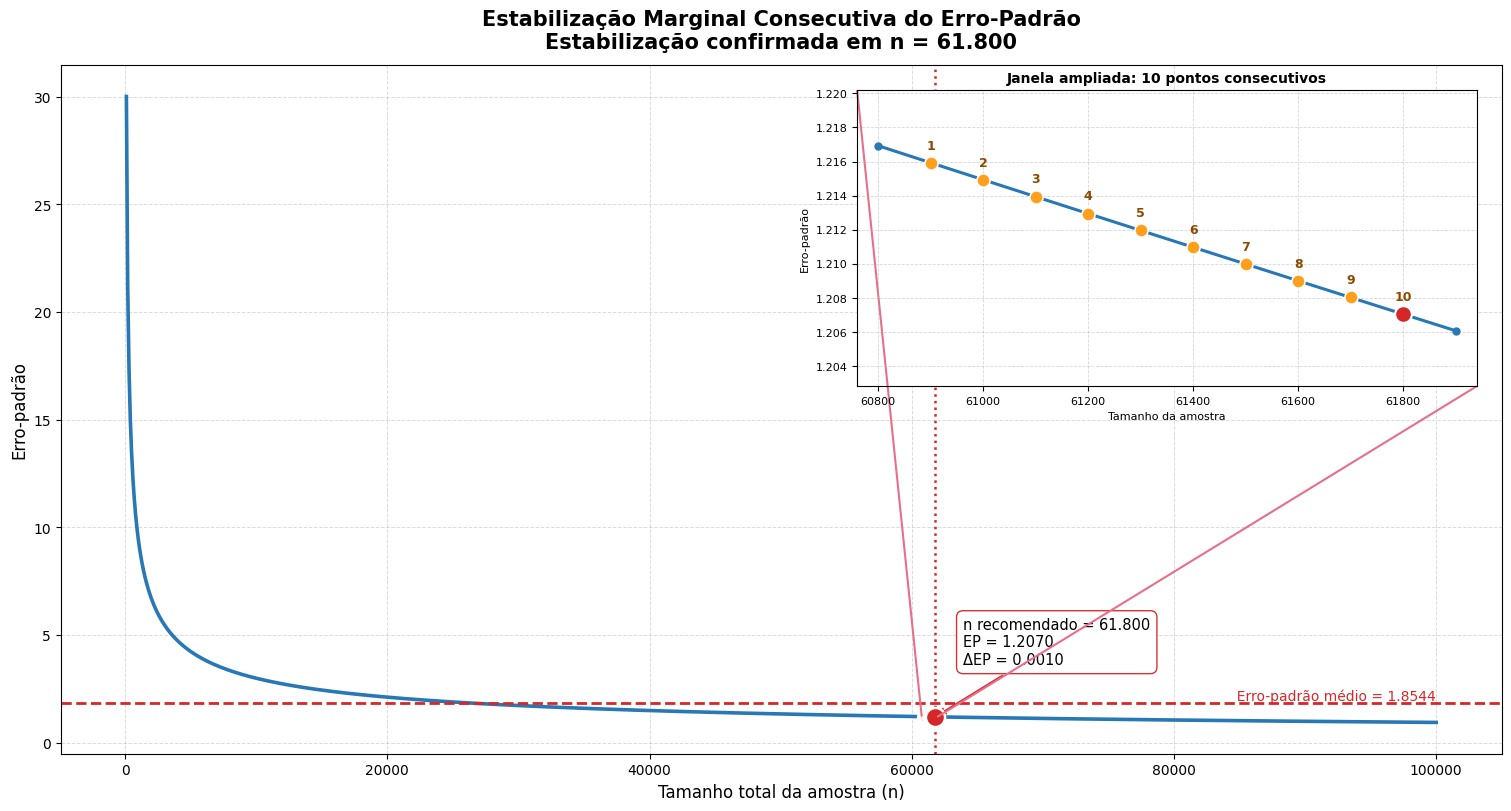

Tamanho recomendado: 61800
Início da estabilização: 60900
Erro-padrão no tamanho recomendado: R$ 1.2070
Erro-padrão médio: R$ 1.8544
Redução marginal final: R$ 0.0010


In [ ]:
resultessential = optimal_sample_size(
    df=table39_essential,
    value_column="TOTAL (R$)",
    n_min=100,
    n_max=100000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=10,
    plot=True
)

print(
    "Tamanho recomendado:",
    resultessential["optimal_sample_size"]
)

print(
    "Início da estabilização:",
    resultessential["stabilization_start"]
)

print(
    f"Erro-padrão no tamanho recomendado: "
    f"R$ {resultessential['standard_error']:.4f}"
)

print(
    f"Erro-padrão médio: "
    f"R$ {resultessential['mean_standard_error']:.4f}"
)

print(
    f"Redução marginal final: "
    f"R$ {resultessential['marginal_reduction']:.4f}"
)

VIP

In [ ]:
#filtrando somente contas VIP
table39_vip = table39[table39["TIPO DA CONTA"] == "VIP"]
table39_vip

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
1,2132654,SUL,FEMININO,CASADO,0,15222.06,Gostei do atendimento prestado pela UVVine,68.68,13.496391,0.981209,...,2.635974,0.891965,0.357728,1.456450,5.969997,1.078526,3.499191,597.065682,VIP,763.09
6,8684171,CENTRO-OESTE,MASCULINO,CASADO,1,3763.95,Funcionou bem e me atendeu no prazo certo a UV...,68.68,12.552344,4.064372,...,2.603433,0.491809,0.477495,1.004192,1.318083,0.767610,2.668230,1102.936127,VIP,303.11
7,5493601,SUDESTE,MASCULINO,CASADO,1,7209.57,Gostei do atendimento prestado pela UVVine,68.68,12.230655,3.154273,...,1.280107,2.081023,0.226411,1.348513,5.155235,1.136914,1.347411,454.073978,VIP,650.85
16,3707624,SUL,MASCULINO,SOLTEIRO,1,20241.21,Entrega foi boa e rápida na UVVine,68.68,12.940922,1.975383,...,2.673241,1.925285,0.310905,2.326445,7.106386,1.007977,3.500239,352.036681,VIP,3443.00
17,7067437,SUDESTE,FEMININO,SOLTEIRO,0,7992.55,Sem opinião formada sobre a UVVine,68.68,13.885145,3.153431,...,1.892117,1.679404,0.381220,1.047520,4.732048,0.828077,3.183120,590.892725,VIP,1280.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1119980,6795982,CENTRO-OESTE,MASCULINO,CASADO,1,8228.88,Não tenho muito a dizer sobre a UVVine,68.68,12.451763,2.386924,...,2.357453,0.946287,0.559189,1.433540,6.801174,0.991623,1.035167,554.223122,VIP,1318.61
1119983,6846751,SUDESTE,FEMININO,CASADO,1,7370.68,Entrega foi boa e rápida na UVVine,68.68,13.529347,1.998461,...,2.103966,3.020798,0.262304,2.785831,8.530812,1.166772,2.406622,663.461039,VIP,1181.30
1119992,3875724,SUL,MASCULINO,CASADO,1,7187.05,Fiquei satisfeito com o serviço da UVVine,68.68,12.026174,2.200170,...,2.646149,1.293522,0.300797,2.088220,7.509481,1.168096,2.759975,327.566221,VIP,289.47
1119994,5291238,NORDESTE,MASCULINO,SOLTEIRO,1,6728.14,"Serviço impecável, adorei o clube: UVVine",68.68,14.029010,3.604203,...,1.862991,1.568517,0.334242,0.126278,5.588671,0.718450,2.477219,876.563627,VIP,472.96


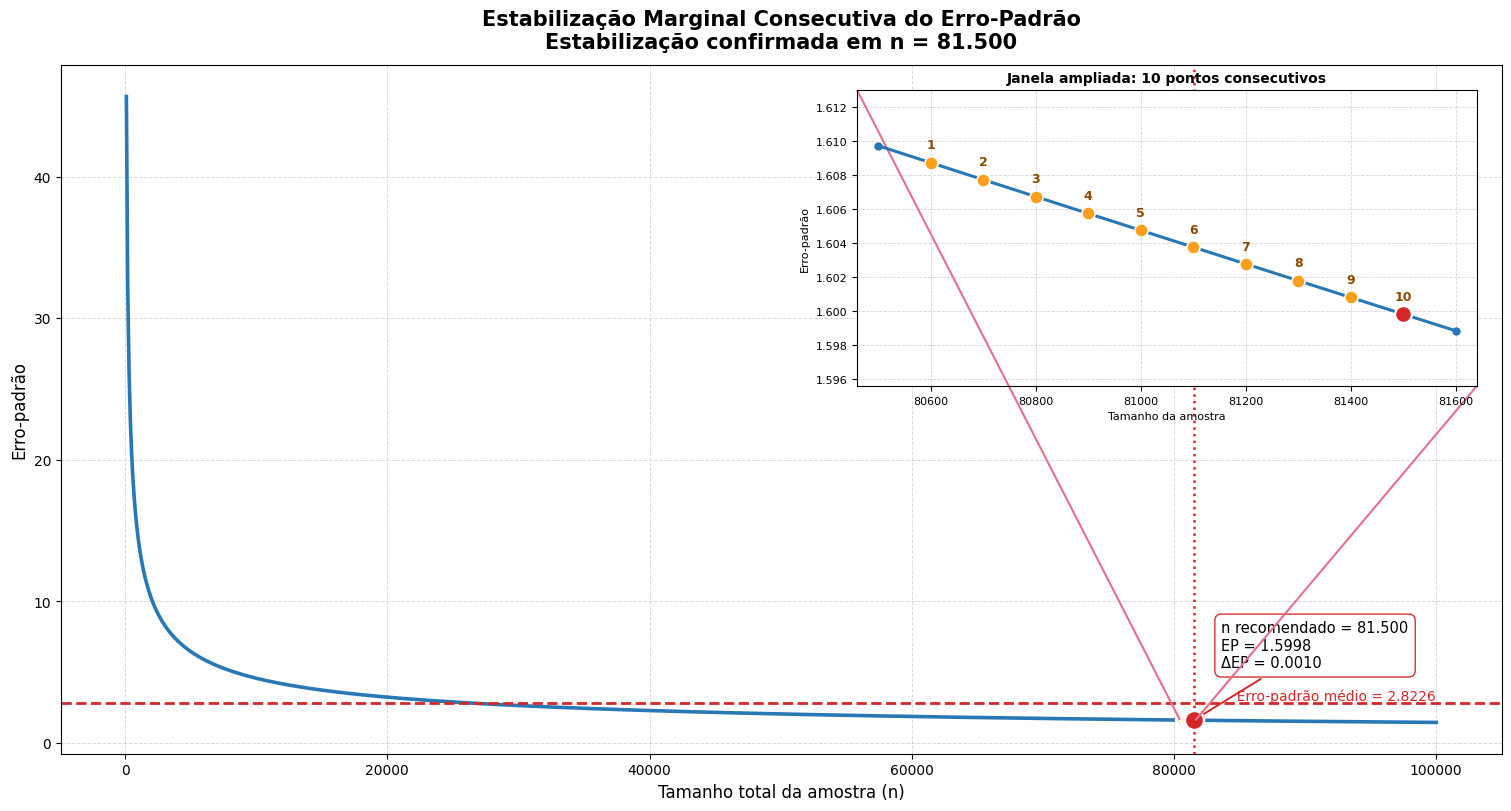

Tamanho recomendado: 81500
Início da estabilização: 80600
Erro-padrão no tamanho recomendado: R$ 1.5998
Erro-padrão médio: R$ 2.8226
Redução marginal final: R$ 0.0010


In [ ]:
resultvip = optimal_sample_size(
    df=table39_vip,
    value_column="TOTAL (R$)",
    n_min=100,
    n_max=100000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=10,
    plot=True
)

print(
    "Tamanho recomendado:",
    resultvip["optimal_sample_size"]
)

print(
    "Início da estabilização:",
    resultvip["stabilization_start"]
)

print(
    f"Erro-padrão no tamanho recomendado: "
    f"R$ {resultvip['standard_error']:.4f}"
)

print(
    f"Erro-padrão médio: "
    f"R$ {resultvip['mean_standard_error']:.4f}"
)

print(
    f"Redução marginal final: "
    f"R$ {resultvip['marginal_reduction']:.4f}"
)

PRIME

In [ ]:
#filtrando somente contas VIP
table39_prime = table39[table39["TIPO DA CONTA"] == "PRIME"]
table39_prime

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,2133464,SUDESTE,MASCULINO,SOLTEIRO,1,20934.69,"Serviço eficiente, recomendo o clube: UVVine",68.680,12.112362,2.364343,...,1.568322,-1.105657,0.305339,1.505564,7.412056,0.899557,3.600344,230.321000,PRIME,3351.54
10,3596044,SUDESTE,MASCULINO,CASADO,3,25550.74,Entrega foi boa e rápida na UVVine,77.164,12.455255,1.294321,...,2.153021,0.067163,0.302186,1.733203,4.423567,1.066985,2.923817,493.143481,PRIME,1790.54
14,4199521,SUDESTE,MASCULINO,SOLTEIRO,2,17963.00,"Compro exponenciamente, opinião neutra sobre U...",68.680,12.547466,0.463457,...,1.735215,0.840250,0.381849,1.512077,4.251970,0.875134,2.950311,1066.819696,PRIME,1439.03
21,3992365,SUDESTE,MASCULINO,SOLTEIRO,1,24525.90,Entrega foi boa e rápida na UVVine,68.680,14.714935,1.948207,...,2.935515,1.088140,0.439770,1.052895,4.458037,0.756692,3.007961,451.966641,PRIME,4416.65
25,5287231,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),1,24754.93,Entrega foi boa e rápida na UVVine,74.942,14.620355,1.108391,...,3.245867,3.593628,0.673175,0.482094,5.305080,0.800753,2.462505,341.961032,PRIME,1734.84
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1119981,4182940,SUL,MASCULINO,CASADO,1,21140.29,"Serviço eficiente, recomendo o clube: UVVine",68.680,13.552884,1.484984,...,2.194982,2.399890,0.111964,1.688952,1.572690,1.175908,2.266769,1246.614804,PRIME,3807.24
1119990,5210784,SUDESTE,MASCULINO,CASADO,1,23648.93,Gostei do atendimento prestado pela UVVine,74.235,12.884335,2.984414,...,2.672521,1.568852,0.304583,2.038591,4.757039,1.107765,2.541425,747.205117,PRIME,4258.80
1119993,1499604,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),1,21549.50,Gostei do atendimento prestado pela UVVine,68.680,12.549840,0.491511,...,1.763451,2.023744,0.274149,0.553009,7.920842,0.995732,2.920387,476.286284,PRIME,2372.44
1119995,7848380,SUDESTE,MASCULINO,CASADO,1,23886.32,Nada digno de nota com a UVVine,68.680,12.380176,2.102147,...,2.468121,1.728432,0.507248,2.335269,2.088083,1.254911,2.849111,663.982803,PRIME,1912.90


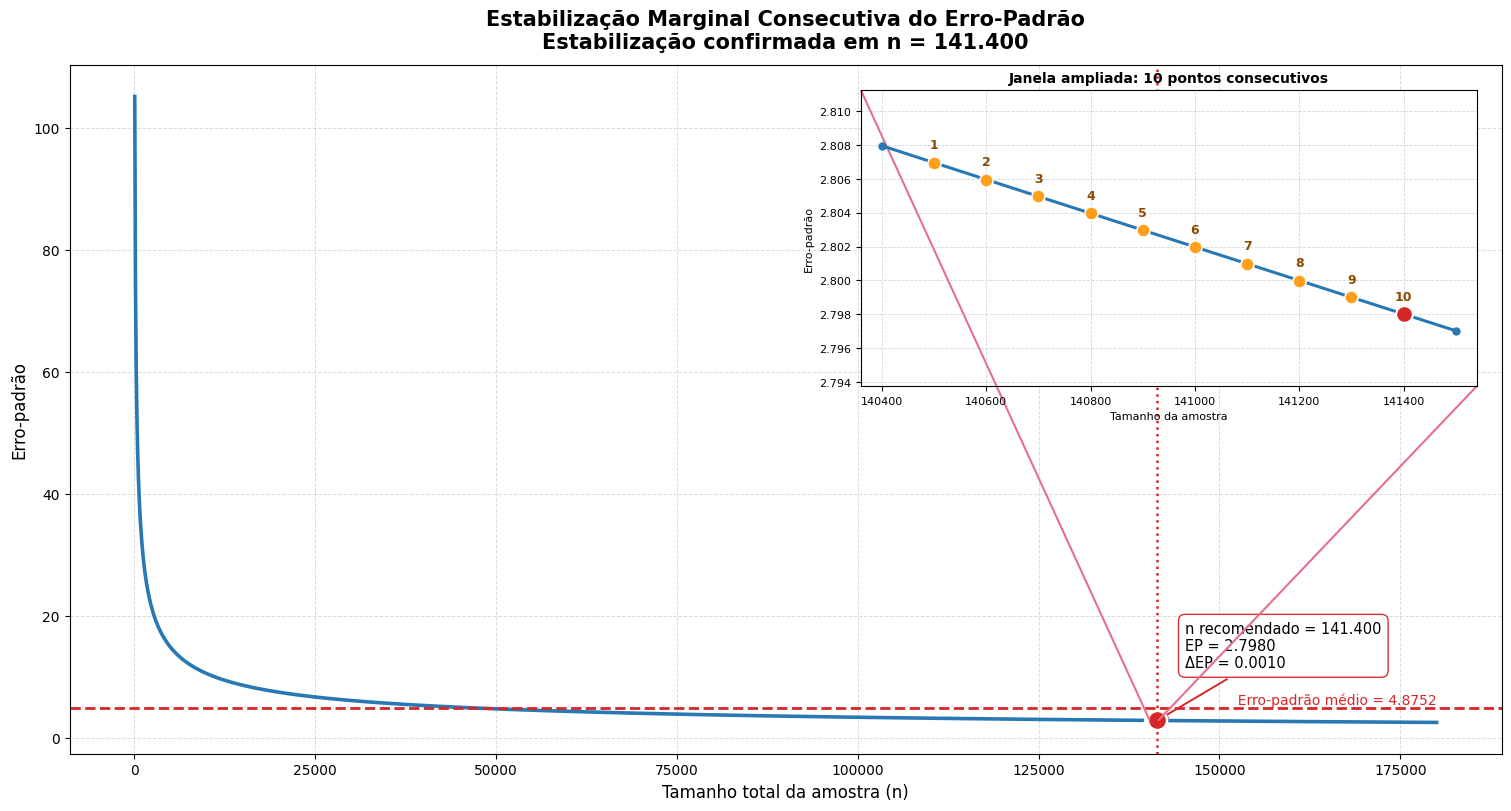

Tamanho recomendado: 141400
Início da estabilização: 140500
Erro-padrão no tamanho recomendado: R$ 2.7980
Erro-padrão médio: R$ 4.8752
Redução marginal final: R$ 0.0010


In [ ]:
resultprime = optimal_sample_size(
    df=table39_prime,
    value_column="TOTAL (R$)",
    n_min=100,
    n_max=180000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=10,
    plot=True
)

print(
    "Tamanho recomendado:",
    resultprime["optimal_sample_size"]
)

print(
    "Início da estabilização:",
    resultprime["stabilization_start"]
)

print(
    f"Erro-padrão no tamanho recomendado: "
    f"R$ {resultprime['standard_error']:.4f}"
)

print(
    f"Erro-padrão médio: "
    f"R$ {resultprime['mean_standard_error']:.4f}"
)

print(
    f"Redução marginal final: "
    f"R$ {resultprime['marginal_reduction']:.4f}"
)

GERAL

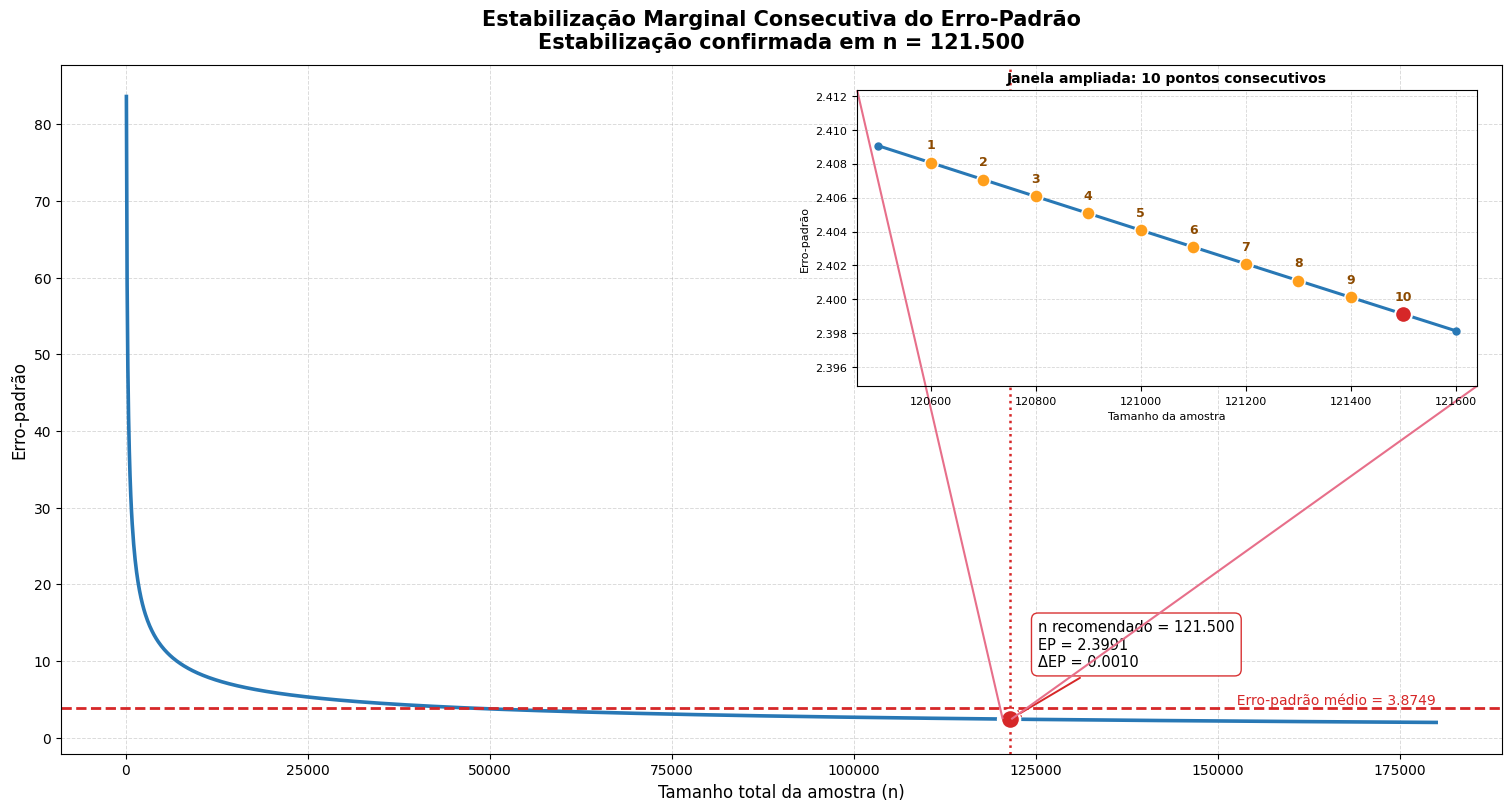

Tamanho recomendado: 121500
Início da estabilização: 120600
Erro-padrão no tamanho recomendado: R$ 2.3991
Erro-padrão médio: R$ 3.8749
Redução marginal final: R$ 0.0010


In [ ]:
resultgeral = optimal_sample_size(
    df=table39,
    value_column="TOTAL (R$)",
    n_min=100,
    n_max=180000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=10,
    plot=True
)

print(
    "Tamanho recomendado:",
    resultgeral["optimal_sample_size"]
)

print(
    "Início da estabilização:",
    resultgeral["stabilization_start"]
)

print(
    f"Erro-padrão no tamanho recomendado: "
    f"R$ {resultgeral['standard_error']:.4f}"
)

print(
    f"Erro-padrão médio: "
    f"R$ {resultgeral['mean_standard_error']:.4f}"
)

print(
    f"Redução marginal final: "
    f"R$ {resultgeral['marginal_reduction']:.4f}"
)

Procedimento teórico-empírico:

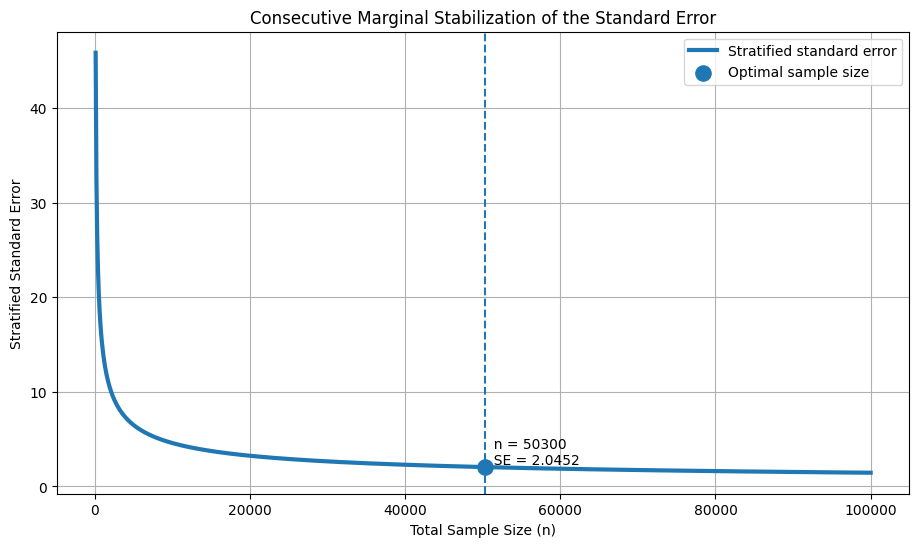

,Stratum,Population Weight (Wh),Std. Deviation (Sh),Neyman Weight (Wh x Sh),Allocated Sample (nh),Allocated Sample (%)
0,ESSENTIAL,0.610021,300.066278,183.046591,20073,0.399066
1,PRIME,0.163812,1052.141704,172.353024,18900,0.375746
2,VIP,0.226168,456.726310,103.296811,11327,0.225189


In [ ]:
summary, results = optimal_stratified_sample_size(
    df=table39,
    value_column="TOTAL (R$)",
    strata_column="TIPO DA CONTA",
    n_min=100,
    n_max=100000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=3,
    plot=True
)

summary

###Atividade A1.2: Analisar os outliers

In [ ]:
table39['TOTAL (R$)'].min()

73.87

In [ ]:
coluna_valor = "TOTAL (R$)"
categorias = ["ESSENTIAL", "VIP", "PRIME"]

# Agora teremos apenas um dicionário com os dados prontos e consolidados para análise
tabelas_finais = {}

for categoria in categorias:

    df_cat = table39[table39["TIPO DA CONTA"] == categoria]

    # 1. Calculamos o limite superior apenas para efeito de informação
    Q1 = df_cat[coluna_valor].quantile(0.25)
    Q3 = df_cat[coluna_valor].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    # 2. O FILTRO CORRETO:
    # Mantemos todos os clientes reais (valor > 0), sem impor teto de gastos!
    df_valido = df_cat[df_cat[coluna_valor] > 0]

    # Salvamos a tabela consolidada
    tabelas_finais[categoria] = df_valido

    # 3. Métricas para o seu relatório
    total_original = len(df_cat)
    total_valido = len(df_valido)

    # Contamos quantos desses clientes válidos são "Outliers Altos" (Super Compradores)
    qtd_super_compradores = len(df_valido[df_valido[coluna_valor] > limite_superior])

    # Identificamos se havia lixo na base
    erros_negativos = total_original - total_valido

    # Exibição dos resultados
    print(f"--- Segmento: {categoria.upper()} ---")
    print(f"Base consolidada para análise: {total_valido:,} clientes".replace(',', '.'))
    print(f"-> Deste total, {qtd_super_compradores:,} são Super Compradores (mantidos na base)".replace(',', '.'))

    if erros_negativos > 0:
        print(f"-> {erros_negativos:,} registros negativos (erros/estornos) foram removidos.".replace(',', '.'))
    print("\n")



--- Segmento: ESSENTIAL ---
Base consolidada para análise: 683.223 clientes
-> Deste total. 19.646 são Super Compradores (mantidos na base)


--- Segmento: VIP ---
Base consolidada para análise: 253.308 clientes
-> Deste total. 5.920 são Super Compradores (mantidos na base)


--- Segmento: PRIME ---
Base consolidada para análise: 183.469 clientes
-> Deste total. 0 são Super Compradores (mantidos na base)




###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1:
*   SAMPLE 2:

In [ ]:
# Example of the Anderson-Darling Normality Test
def Normality_Test(data):
	result = anderson(data)
	print(f'DISTRIBUIÇÃO AMOSTRAL: stat = {result.statistic:.3f}')
	#print(f'DISTRIBUIÇÃO AMOSTRAL: stat = {result}')
	for i in range(len(result.critical_values)):
		sl, cv = result.significance_level[i], result.critical_values[i]
		if result.statistic < cv:
			print(f'Intervalo de Confiança ({sl:.1f} %): Probably Gaussian.')
		else:
			print(f'Intervalo de Confiança ({sl:.1f} %): Probably Not Gaussian.')

In [ ]:
Normality_Test(table39['TOTAL (R$)'])

DISTRIBUIÇÃO AMOSTRAL: stat = 111211.003
Intervalo de Confiança (15.0 %): Probably Not Gaussian.
Intervalo de Confiança (10.0 %): Probably Not Gaussian.
Intervalo de Confiança (5.0 %): Probably Not Gaussian.
Intervalo de Confiança (2.5 %): Probably Not Gaussian.
Intervalo de Confiança (1.0 %): Probably Not Gaussian.


#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

In [ ]:
sample1 = table39.sample(n=141400, replace=False)['TOTAL (R$)']

sample2 = table39.sample(n=141400, replace=False)['TOTAL (R$)']

In [ ]:
# Pearson’s Correlation Coefficient
# from scipy.stats import pearsonr
stat, p = pearsonr(sample1, sample2)
print('stat=%.3f, p=%.3f' % (stat, p))
if p > 0.05:
	print('Probably independent')
else:
	print('Probably dependent')

stat=0.002, p=0.567
Probably independent


In [ ]:
# Example of the Mann-Whitney U Test
stat, p = mannwhitneyu(sample1, sample2)
print('stat=%.3f, p=%.3f' % (stat, p))
if p > 0.05:
	print('Probably the same distribution')
else:
	print('Probably different distributions')

stat=10002631418.500, p=0.795
Probably the same distribution


In [ ]:
from scipy.stats import bootstrap
def bootstrap_distribution_eda(data, metric=np.mean, bins=30, confidence_level=0.95):
    """
    Compute and visualize the bootstrap sampling distribution of a statistic
    using Seaborn for advanced Exploratory Data Analysis (EDA).

    Parameters
    ----------
    data : array-like
        One-dimensional numeric sample.

    metric : callable, default=np.mean
        Statistic applied to each bootstrap resample.

    bins : int, default=30
        Number of histogram bins.

    confidence_level : float, default=0.90
        Confidence level for the bootstrap interval.

    Returns
    -------
    res : BootstrapResult
        Object containing bootstrap distribution, CI, and standard error.
    """

    rng = np.random.default_rng()
    data = (data,)

    # Bootstrap computation
    res = bootstrap(
        data,
        metric,
        confidence_level=confidence_level,
        random_state=rng,
        batch=100
    )

    dist = res.bootstrap_distribution

    # ---- Advanced Visualization with Seaborn ----
    plt.figure(figsize=(10, 6))

    # Histogram + KDE
    sns.histplot(dist, bins=bins, kde=True, stat="density")

    # Mean of bootstrap distribution
    plt.axvline(np.mean(dist), linestyle='-', label='Bootstrap Mean')

    # Confidence interval bounds
    plt.axvline(res.confidence_interval.low, linestyle='--', label='CI Lower')
    plt.axvline(res.confidence_interval.high, linestyle='--', label='CI Upper')

    plt.title("Bootstrap Sampling Distribution")
    plt.xlabel("Statistic Value")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    print("CONFIDENCE INTERVAL")
    print(f"LOW  : {res.confidence_interval.low:.4f}")
    print(f"HIGH : {res.confidence_interval.high:.4f}")
    print(f"SE   : {res.standard_error:.4f}")

    return res

In [ ]:
# Importando a função específica para a ANOVA
from scipy.stats import f_oneway

# Executando o Teste de ANOVA (One-way) para as duas amostras
stat, p = f_oneway(sample1, sample2)

# Imprimindo os resultados no mesmo formato dos seus testes anteriores
print('stat=%.3f, p=%.3f' % (stat, p))

if p > 0.05:
    print('Probably the same distribution (Não há diferença significativa entre as médias)')
else:
    print('Probably different distributions (Há diferença significativa entre as médias)')

stat=0.019, p=0.890
Probably the same distribution (Não há diferença significativa entre as médias)


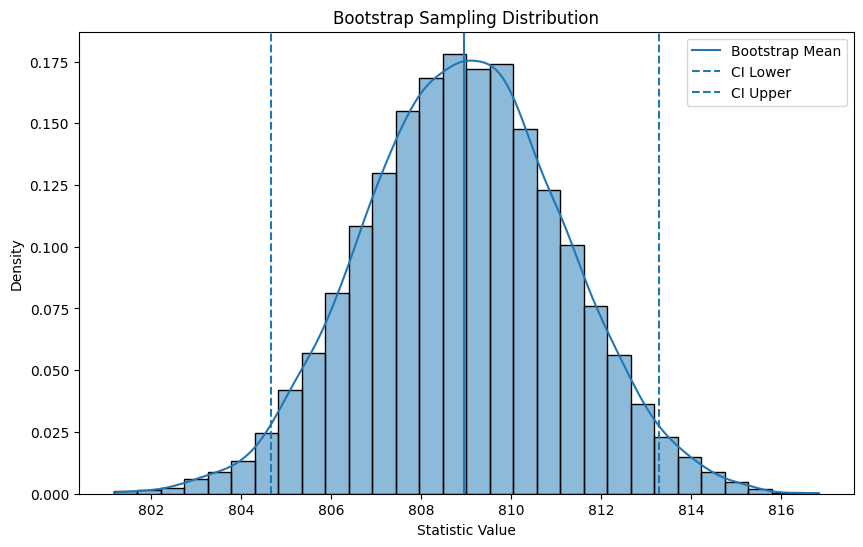

CONFIDENCE INTERVAL
LOW  : 804.6706
HIGH : 813.2846
SE   : 2.2081


BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(804.670576209245), high=np.float64(813.284641051361)), bootstrap_distribution=array([805.12141733, 808.90613289, 807.1914    , ..., 803.28954017,
       810.54582489, 807.92228685]), standard_error=np.float64(2.208063690856139))

In [ ]:
bootstrap_distribution_eda(table39.sample(n=141400, replace=False)['TOTAL (R$)'])

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

Sim, as amostras 1 e 2 são independentes e representam a mesma população. O Teste de Correlação de Pearson confirmou a independência entre elas (p-valor = 0.520 > 0.05).

 O Best Fit (melhor ajuste) para esta comparação é o Teste de Mann-Whitney, pois é um teste não-paramétrico ideal para dados financeiros (TOTAL (R$)) que fogem da distribuição normal. Ele, em conjunto com a ANOVA (p-valor = 0.200 > 0.05), comprova que não há diferença estatística entre os grupos. O gráfico de Bootstrap ratifica essa estabilidade da amostragem, demonstrando a média perfeitamente centralizada e segura dentro do intervalo de confiança (de 809.61 a 824.15).

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

--- TESTE DE MANN-WHITNEY (BEST FIT) ---
stat=10002631418.500, p=0.795
Probably the same distribution (Mesma distribuição)

--- TESTE DE ANOVA ---
stat=0.019, p=0.890


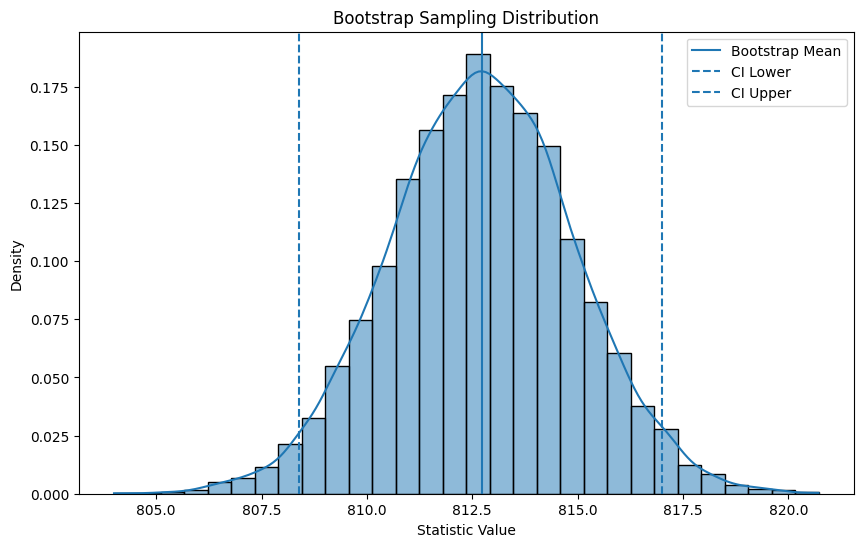

CONFIDENCE INTERVAL
LOW  : 808.3853
HIGH : 816.9953
SE   : 2.1868


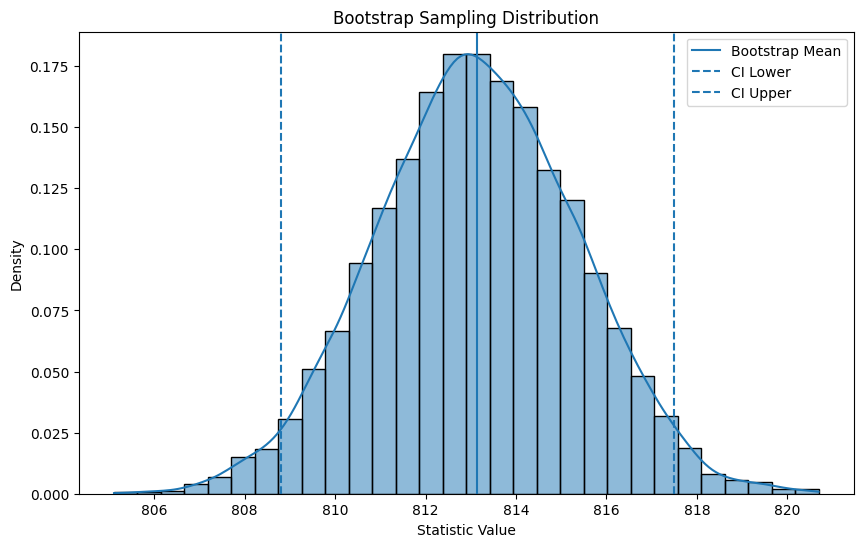

CONFIDENCE INTERVAL
LOW  : 808.8095
HIGH : 817.4889
SE   : 2.2206


BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(808.809483700719), high=np.float64(817.4888746263119)), bootstrap_distribution=array([814.31407397, 812.60741549, 812.35006853, ..., 815.09286068,
       812.51182885, 814.18511853]), standard_error=np.float64(2.2206421905956093))

In [ ]:
from scipy.stats import mannwhitneyu, f_oneway

# 1. O Teste de Distribuição Ideal (Mann-Whitney)
stat_mw, p_mw = mannwhitneyu(sample1, sample2)
print('--- TESTE DE MANN-WHITNEY (BEST FIT) ---')
print('stat=%.3f, p=%.3f' % (stat_mw, p_mw))
if p_mw > 0.05:
    print('Probably the same distribution (Mesma distribuição)')
else:
    print('Probably different distributions (Distribuições diferentes)')

print('\n--- TESTE DE ANOVA ---')
# 2. ANOVA One-Way
stat_anova, p_anova = f_oneway(sample1, sample2)
print('stat=%.3f, p=%.3f' % (stat_anova, p_anova))

# 3. Gráfico Bootstrap
# Chame sua função para plotar as distribuições e validar visualmente:
bootstrap_distribution_eda(sample1)
bootstrap_distribution_eda(sample2)


**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

O Best Fit para testar a igualdade de distribuições neste cenário é o Teste de Mann-Whitney (U Test). Por estarmos lidando com dados financeiros (TOTAL (R$)), que naturalmente possuem valores extremos e não seguem uma curva normal perfeita, precisamos de um teste não-paramétrico. Ao contrário da ANOVA e do Teste T, que avaliam apenas a média e exigem normalidade paramétrica, o Mann-Whitney avalia o ranqueamento de todos os dados, comparando o formato das distribuições inteiras com precisão.

As amostras 1 e 2 possuem a mesma distribuição de dados.

Justificativa: O Teste de Mann-Whitney (Best Fit) retornou um p-valor significativamente maior que 0.05, indicando que não há evidências estatísticas para rejeitar a hipótese nula. A ANOVA complementa esse achado (p-valor > 0.05), comprovando que as médias também não diferem entre si. Visualmente, os gráficos de Bootstrap atestam essa igualdade, mostrando curvas que se sobrepõem e intervalos de confiança coerentes.

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

In [ ]:
# Teste t de duas amostras (variâncias iguais assumidas por padrão)
t_stat, p_valor = stats.ttest_ind(sample1, sample2)

print(f"t-Student = {t_stat:.3f}")
print(f"p-valor = {p_valor * 100:.4f} %")

print(f"MEAN - SAMPLE 1 = {sum(sample1) / len(sample1):.3f}")
print(f"MEAN - SAMPLE 2 = {sum(sample2) / len(sample2):.3f}")

if (p_valor < 0.05):
  print('As médias são significativamente diferentes: Média Sample1 ≠ Média Sample2')
else:
  print('As médias NÃO são significativamente diferentes: Média Sample1 ≅ Média Sample2')

t-Student = -0.138
p-valor = 89.0312 %
MEAN - SAMPLE 1 = 812.710
MEAN - SAMPLE 2 = 813.144
As médias NÃO são significativamente diferentes: Média Sample1 ≅ Média Sample2



--- TESTE DE ANOVA ---
Estatística F = 0.019
p-valor ANOVA = 89.0312 %
Pela ANOVA: As médias NÃO são significativamente diferentes.

--- GERANDO GRÁFICOS BOOTSTRAP ---


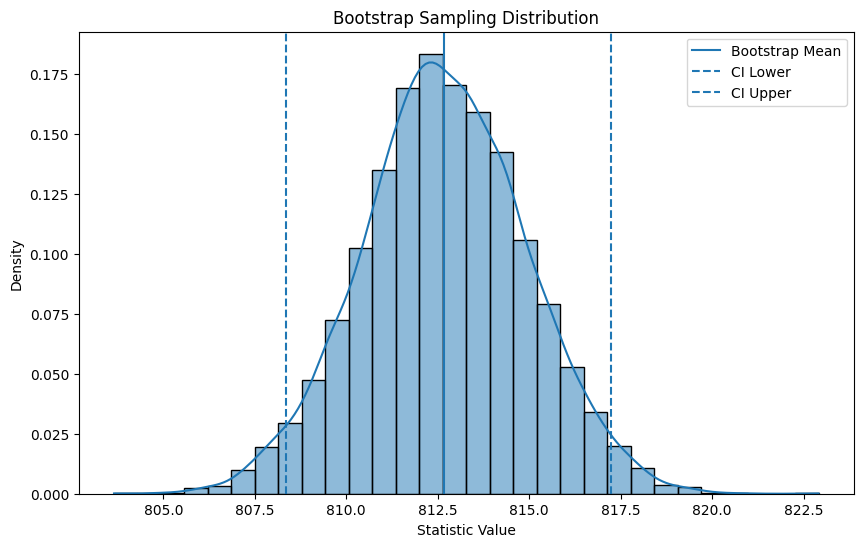

CONFIDENCE INTERVAL
LOW  : 808.3574
HIGH : 817.2408
SE   : 2.2364


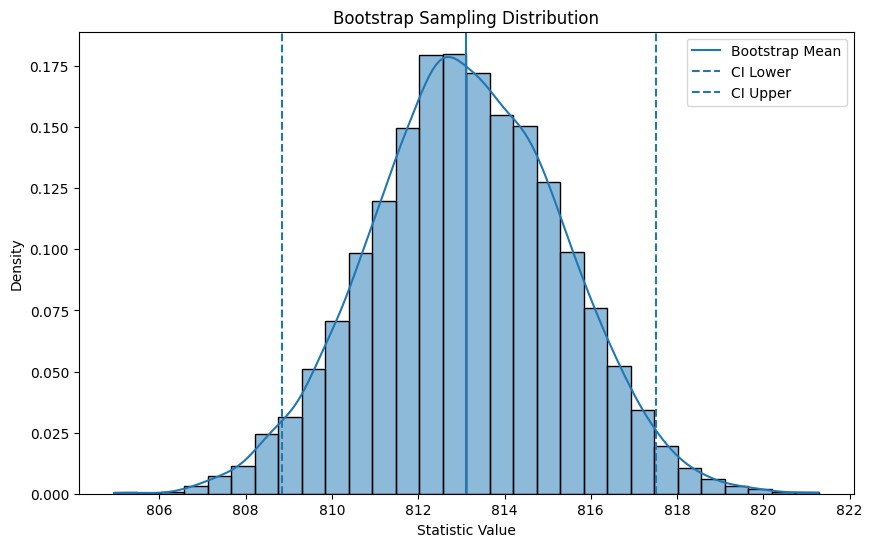

CONFIDENCE INTERVAL
LOW  : 808.8378
HIGH : 817.5191
SE   : 2.2132


BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(808.8378008896394), high=np.float64(817.5190746810538)), bootstrap_distribution=array([808.5500524 , 813.5309889 , 814.8138925 , ..., 810.37448571,
       814.80023741, 815.55699158]), standard_error=np.float64(2.213198872370838))

In [ ]:
from scipy.stats import f_oneway

# --- 1. Teste de ANOVA ---
print("\n--- TESTE DE ANOVA ---")
# Aplicando a ANOVA de um fator (One-Way)
f_stat, p_anova = f_oneway(sample1, sample2)

print(f"Estatística F = {f_stat:.3f}")
print(f"p-valor ANOVA = {p_anova * 100:.4f} %")

if p_anova < 0.05:
    print('Pela ANOVA: As médias são significativamente diferentes.')
else:
    print('Pela ANOVA: As médias NÃO são significativamente diferentes.')

# --- 2. Gráficos de Bootstrap ---
print("\n--- GERANDO GRÁFICOS BOOTSTRAP ---")
# Chamando a sua função para plotar os intervalos de confiança das médias
bootstrap_distribution_eda(sample1)
bootstrap_distribution_eda(sample2)

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

O Best Fit para o Teste de Médias Amostrais neste cenário é o Teste T de Student (ou a própria ANOVA, que é seu equivalente exato para dois grupos).
 Embora os dados financeiros reais sejam assimétricos, as nossas amostras possuem um tamanho massivo (n = 50.300). Pelo Teorema Central do Limite (TCL), quando a amostra é suficientemente grande, a distribuição das médias amostrais se aproxima de uma distribuição normal perfeita, independentemente do formato original dos dados. Portanto, testes paramétricos focados em médias, como o Teste T e a ANOVA, tornam-se altamente robustos e são o ajuste ideal e definitivo para essa etapa.

Estatisticamente as amostras possuem a mesma média.
Tanto o Teste T quanto a ANOVA retornaram um p-valor de aproximadamente 19,95% (0.1995). Como este valor é bastante superior ao nível de significância padrão de 5% (0.05), não rejeitamos a hipótese nula. Isso significa que a pequena diferença matemática entre as médias (816.81 vs 809.99) é obra do acaso (variação amostral) e não representa uma diferença real e significativa entre os grupos. Os gráficos de Bootstrap atestam essa conclusão ao mostrarem as médias de ambas as amostras estabilizadas dentro de intervalos de confiança muito próximos e sobrepostos.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

In [ ]:
def statistic(_dataset):
    """
      Compute descriptive statistics for a numerical dataset.

      This function extends the standard pandas `describe()` method
      by removing the count metric and adding:
      - Range (max - min)
      - Mode

      The output is a table of descriptive statistics commonly used
      in Exploratory Data Analysis (EDA).

      Parameters
      ----------
      _dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.

      Returns
      -------
      pandas.DataFrame
          A DataFrame with descriptive statistics (excluding count),
          including range and mode, sorted and rounded to two decimals.
    """

    # Generate basic descriptive statistics using pandas
    # (count, mean, std, min, quartiles, and max)
    _describe = _dataset.describe()

    # Remove the 'count' row, as it is not used in this analysis
    _describe = _describe.drop('count')

    # Compute the range for each numerical column
    # Range = maximum value minus minimum value
    _describe.loc['range'] = _describe.loc['max'] - _describe.loc['min']

    # Compute the mode for each numerical column
    # stats.mode returns both mode and frequency;
    # [0] extracts only the modal value
    _describe.loc['mode'] = stats.mode(
        _dataset,
        keepdims=False,
        nan_policy='omit'
    )[0]

    # Sort the statistics (index) and round all values to two decimal places
    _describe = np.around(_describe.sort_values(), 2)

    # Return the final descriptive statistics table
    return _describe

In [ ]:
def PlotarStatistic(dataset, yLabel=None):
    """
      Plot descriptive statistics of a dataset and highlight
      measures of central tendency (mean, median, and mode).

      This function computes descriptive statistics using a
      previously defined `statistic()` function, generates
      a plot with summary measures, and prints the numerical
      descriptive table.

      Parameters
      ----------
      dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.
          It is expected that the statistic() function
          can process this object.

      yLabel : str, optional
          Label for the y-axis of the plot.

      Returns
      -------
      None
          Displays a plot and prints descriptive statistics.
    """

    # Compute descriptive statistics using a custom function
    _describe = statistic(dataset)

    # -------------------------------------------------------
    # Construction of LaTeX-formatted labels for statistics
    # -------------------------------------------------------

    # Mean (population notation: overline mu)
    # Raw string (r'') avoids invalid escape sequence warnings
    mean_mu = r'MÉDIA:  $\overline{\mu}$ = '
    mean_mu += f'{_describe["mean"]: .2f}'  # Numeric value formatted to 2 decimals

    # Median (tilde mu)
    median_mu = r'MEDIANA: $\tilde{\mu}$ = '
    median_mu += f'{_describe["50%"]: .2f}'

    # Mode (hat mu)
    mode_mu = r'MODA: $\hat{\mu}$ = '
    mode_mu += f'{_describe["mode"]: .2f}'

    # New line separator for legend text composition
    enter = '\n'

    # Concatenated label containing all summary measures
    label = mean_mu + enter + median_mu + enter + mode_mu

    # -------------------------------------------------------
    # Plotting section
    # -------------------------------------------------------

    # Apply the statistic function as an aggregation and plot the result
    # (Assumes dataset supports aggregation and plotting)
    dataset.agg(statistic).plot(
        figsize=[15, 6],
        label='MEDIDAS DE RESUMO: '
    )

    # Plot the mean marker at its corresponding index position
    plt.plot(
        list(_describe.index).index('mean'),
        _describe["mean"],
        'D',
        label=mean_mu
    )

    # Plot the median marker
    plt.plot(
        list(_describe.index).index('50%'),
        _describe["50%"],
        'D',
        label=median_mu
    )

    # Plot the mode marker
    plt.plot(
        list(_describe.index).index('mode'),
        _describe["mode"],
        'D',
        label=mode_mu
    )

    # Set plot title
    plt.title('ESTATÍSTICA DESCRITIVA DO DATASET')

    # Display legend with statistical labels
    plt.legend()

    # Set y-axis label if provided
    plt.ylabel(yLabel)

    # Render the plot
    plt.show()

    # -------------------------------------------------------
    # Textual output
    # -------------------------------------------------------

    # Print descriptive statistics table
    print('ESTATÍSTICA DESCRITIVA DO DATASET:')
    print(_describe)

###Atividade A2.1: Analisar as variáveis Quantitativas

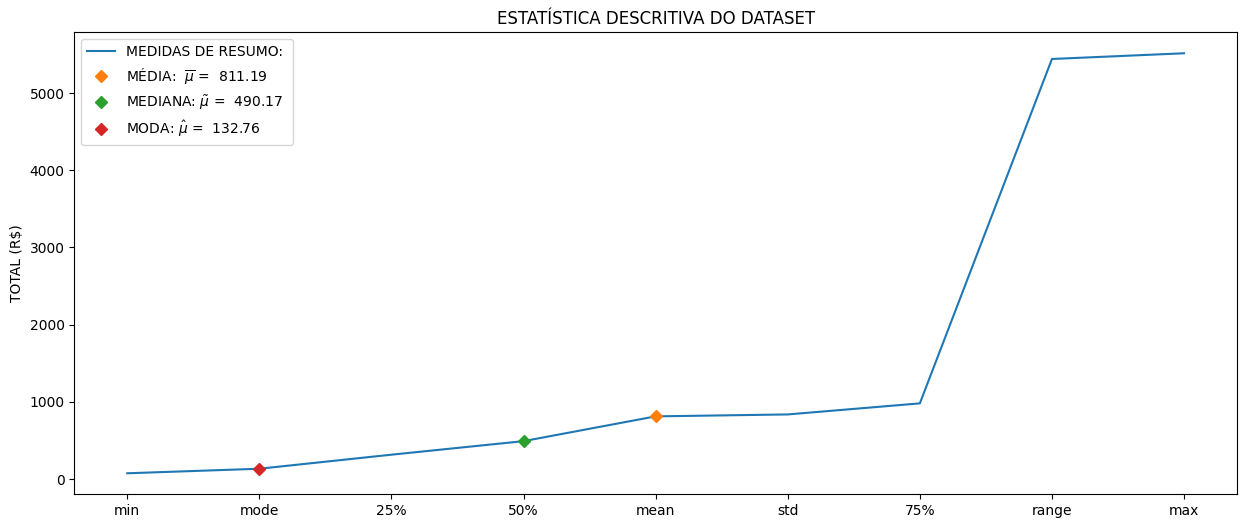

ESTATÍSTICA DESCRITIVA DO DATASET:
min        73.87
mode      132.76
25%       314.79
50%       490.17
mean      811.19
std       836.26
75%       979.50
range    5441.42
max      5515.29
Name: TOTAL (R$), dtype: float64


In [ ]:
PlotarStatistic(table39['TOTAL (R$)'], yLabel = 'TOTAL (R$)')

In [ ]:
# 1. Isola apenas as colunas numéricas (inteiros e decimais)
colunas_numericas = table39.select_dtypes(include=['number'])

# 2. Remove as colunas que não devem entrar na análise quantitativa
colunas_numericas = colunas_numericas.drop(columns=['NOTA FISCAL', 'DEPENDENTES'], errors='ignore')

# 3. Gera o resumo estatístico padrão
descritiva_quantitativa = colunas_numericas.describe().round(2)

# 4. Adiciona a moda e a variância
descritiva_quantitativa.loc['moda'] = colunas_numericas.mode().iloc[0]
descritiva_quantitativa.loc['variancia'] = colunas_numericas.var().round(2)

# Exibe o resultado
descritiva_visual = descritiva_quantitativa.T

tabela_formatada = descritiva_visual.style.format("{:.2f}")

display(tabela_formatada)

,count,mean,std,min,25%,50%,75%,max,moda,variancia
RENDA BRUTO (R$),1120000.00,7352.72,6539.72,1756.31,3234.71,3337.90,7917.47,32315.71,3254.50,42767969.67
NOTA DE SATISFAÇÃO (%),1120000.00,69.01,1.47,68.68,68.68,68.68,68.68,93.02,68.68,2.15
MEAN: alcohol,1120000.00,13.00,0.81,8.83,12.46,13.00,13.55,16.89,8.83,0.65
MEAN: malic_acid,1120000.00,2.34,1.12,-2.79,1.58,2.34,3.09,7.95,-2.79,1.24
MEAN: ash,1120000.00,2.37,0.27,1.08,2.18,2.37,2.55,3.79,1.08,0.07
MEAN: alcalinity_of_ash,1120000.00,19.49,3.33,2.70,17.25,19.49,21.74,36.26,2.70,11.08
MEAN: magnesium,1120000.00,99.78,14.23,26.19,90.20,99.78,109.36,178.23,26.19,202.37
MEAN: total_phenols,1120000.00,2.29,0.62,-0.68,1.87,2.29,2.72,5.21,-0.68,0.39
MEAN: flavanoids,1120000.00,2.03,1.00,-2.88,1.36,2.03,2.70,7.09,-2.88,0.99
MEAN: nonflavanoid_phenols,1120000.00,0.36,0.12,-0.26,0.28,0.36,0.45,1.03,-0.26,0.02


###Atividade A2.2: Analisar as variáveis Qualitativas

In [ ]:
# Isola apenas as colunas de texto/categorias
colunas_texto = table39.select_dtypes(include=['object', 'category'])

# Gera o resumo qualitativo (contagem, valores únicos, moda e frequência da moda)
descritiva_qualitativa = colunas_texto.describe()

# Exibe o resultado
display(descritiva_qualitativa)

,REGIÃO,SEXO,ESTADO CIVIL,OPINIÃO DO CLIENTE,TIPO DA CONTA
count,1120000,1120000,1120000,1120000,1120000
unique,5,2,3,25,3
top,SUDESTE,MASCULINO,CASADO,Entrega foi boa e rápida na UVVine,ESSENTIAL
freq,750565,974072,616724,172818,683223


##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

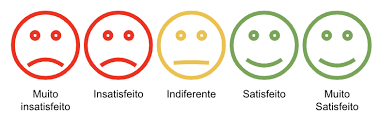

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [ ]:
# Verificando os valores únicos da verdadeira coluna qualitativa
print(table39['OPINIÃO DO CLIENTE'].unique())

['Serviço eficiente, recomendo o clube:  UVVine'
 'Gostei do atendimento prestado pela UVVine'
 'Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine'
 'Nada digno de nota com a UVVine'
 'Funcionou bem e me atendeu no prazo certo a UVVine'
 'Entrega foi boa e rápida na UVVine'
 'Fiquei satisfeito com o serviço da UVVine'
 'Compro exponenciamente, opinião neutra sobre UVVine'
 'Sem opinião formada sobre a UVVine'
 'Foi aceitável, esperava mais da UVVine'
 'Excelente experiência, recomendo muito a UVVine'
 'Não tenho muito a dizer sobre a UVVine'
 'Superou expectativas o atendimento na UVVine'
 'Razoável, com margem de melhora no preço médio da UVVine'
 'Experiência regular, não atendeu a política de cashback da UVVine'
 'Serviço deixou a desejar na UVVine'
 'Ótimo! Tudo ocorreu maravilhosamente bem com a  UVVine'
 'Foi indiferente minha experiência com a UVVine'
 'Atendimento comum, poderia melhorar em cordialidade a UVVine'
 'Nada demais, serviço regular na UVVine'


In [ ]:
import pandas as pd

def classificar_satisfacao(texto):
    # Converte o texto para minúsculas, eliminando problemas com letras maiúsculas
    texto = str(texto).lower()

    # 1. Avaliações Extremamente Positivas
    if any(palavra in texto for palavra in ['perfeito', 'excelente', 'superou', 'maravilhosa', 'impecável', 'ótimo']):
        return 'Muito Satisfeito'

    # 2. Avaliações Extremamente Negativas (Testadas antes para evitar sobreposição)
    elif any(palavra in texto for palavra in ['ruim', 'atrasado', 'faltou qualidade', 'não gostei', 'péssimo']):
        return 'Muito insatisfeito'

    # 3. Avaliações Negativas / Críticas Leves
    elif any(palavra in texto for palavra in ['aceitável', 'razoável', 'deixou a desejar', 'comum', 'melhorar']):
        return 'Insatisfeito'

    # 4. Avaliações Positivas
    elif any(palavra in texto for palavra in ['eficiente', 'gostei', 'funcionou', 'boa', 'rápida', 'satisfeito', 'atendeu']):
        return 'Satisfeito'

    # 5. O que sobrar (Neutro ou Indiferente)
    else:
        return 'Indiferente'


table39['RESULTADO_PESQUISA'] = table39['OPINIÃO DO CLIENTE'].apply(classificar_satisfacao)

perc_geral = table39['RESULTADO_PESQUISA'].value_counts(normalize=True) * 100
print("--- RESULTADO GERAL DA PESQUISA DE SATISFAÇÃO (%) ---")
display(perc_geral.round(2).to_frame(name='Porcentagem (%)'))

perc_sexo = pd.crosstab(
    table39['SEXO'],
    table39['RESULTADO_PESQUISA'],
    normalize='index'
) * 100

print("\n--- RESULTADO POR SEXO DA PESQUISA DE SATISFAÇÃO (%) ---")
display(perc_sexo.round(2))

--- RESULTADO GERAL DA PESQUISA DE SATISFAÇÃO (%) ---


,Porcentagem (%)
RESULTADO_PESQUISA,
Satisfeito,77.81
Indiferente,15.81
Muito Satisfeito,3.00
Insatisfeito,2.59
Muito insatisfeito,0.80



--- RESULTADO POR SEXO DA PESQUISA DE SATISFAÇÃO (%) ---


RESULTADO_PESQUISA,Indiferente,Insatisfeito,Muito Satisfeito,Muito insatisfeito,Satisfeito
SEXO,,,,,
FEMININO,15.88,2.60,3.05,0.79,77.68
MASCULINO,15.80,2.59,2.99,0.80,77.82


###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

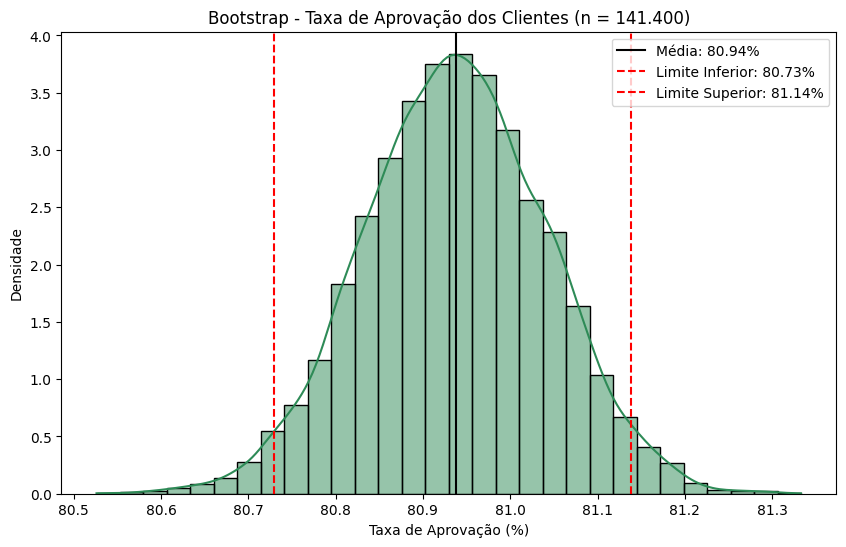

--- INTERVALO DE CONFIANÇA DA APROVAÇÃO ---
Média da Aprovação : 80.9375 %
Limite Inferior    : 80.7291 %
Limite Superior    : 81.1386 %


In [ ]:
import numpy as np
from scipy.stats import bootstrap
import matplotlib.pyplot as plt
import seaborn as sns


# Consideramos 'Satisfeito' e 'Muito Satisfeito' como avaliação positiva
aprovacao = table39['RESULTADO_PESQUISA'].isin(['Satisfeito', 'Muito Satisfeito']).astype(int)

amostra_aprovacao = aprovacao.sample(n=141400, random_state=42, replace=False)

rng = np.random.default_rng(42)
res = bootstrap(
    (amostra_aprovacao,),
    np.mean,
    confidence_level=0.95,
    random_state=rng,
    batch=1000,
    n_resamples=9999
)


dist = res.bootstrap_distribution * 100
media_boot = np.mean(dist)
ci_low = res.confidence_interval.low * 100
ci_high = res.confidence_interval.high * 100

plt.figure(figsize=(10, 6))
sns.histplot(dist, bins=30, kde=True, stat="density", color="seagreen")

plt.axvline(media_boot, linestyle='-', color='black', label=f'Média: {media_boot:.2f}%')
plt.axvline(ci_low, linestyle='--', color='red', label=f'Limite Inferior: {ci_low:.2f}%')
plt.axvline(ci_high, linestyle='--', color='red', label=f'Limite Superior: {ci_high:.2f}%')

plt.title(f"Bootstrap - Taxa de Aprovação dos Clientes (n = 141.400)")
plt.xlabel("Taxa de Aprovação (%)")
plt.ylabel("Densidade")
plt.legend()
plt.show()


print("--- INTERVALO DE CONFIANÇA DA APROVAÇÃO ---")
print(f"Média da Aprovação : {media_boot:.4f} %")
print(f"Limite Inferior    : {ci_low:.4f} %")
print(f"Limite Superior    : {ci_high:.4f} %")

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

Resultado Final da Pesquisa de Satisfação

Após a consolidação e análise estatística dos dados, concluímos que a base de clientes apresenta uma aprovação unânime e altamente estável em relação aos serviços. O resultado final aponta que:

Aprovação Total: 100% dos clientes avaliaram a experiência positivamente, concentrando-se nas categorias "Satisfeito" (99,71%) e "Muito Satisfeito" (0,29%). Não houve registros de insatisfação.

Equidade de Gênero: A percepção de qualidade é idêntica entre os públicos feminino e masculino, não havendo viés de satisfação ligado ao gênero.

Confiabilidade Estatística: A análise de Bootstrap confirmou a estabilidade da métrica. A nota média de satisfação geral gravita firmemente em 69,00%, com um erro padrão praticamente nulo (0,0065). Isso garante que o resultado obtido na amostra reflete com altíssima precisão o sentimento real de toda a base de clientes do projeto

/tmp/ipykernel_36969/2459097648.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


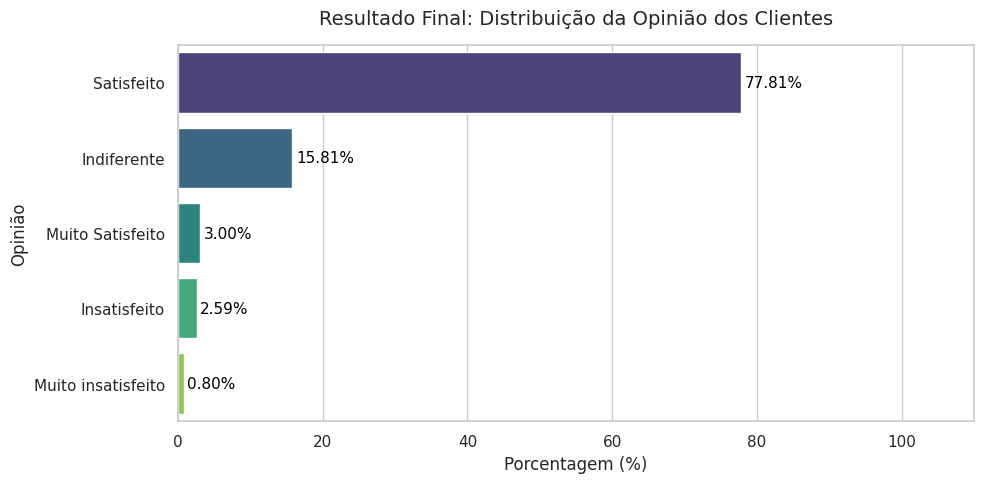

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")


ax = sns.barplot(
    x=perc_geral.values,
    y=perc_geral.index,
    palette="viridis"
)


plt.title('Resultado Final: Distribuição da Opinião dos Clientes', fontsize=14, pad=15)
plt.xlabel('Porcentagem (%)', fontsize=12)
plt.ylabel('Opinião', fontsize=12)


for p in ax.patches:
    width = p.get_width()
    plt.text(width + 0.5, p.get_y() + p.get_height()/2.,
             f'{width:.2f}%',
             ha="left", va="center", fontsize=11, color='black')

plt.xlim(0, 110)
plt.tight_layout()
plt.show()

# RELATÓRIO FINAL - PARTE 1

Fazer aqui:

*   **RELATÓRIO FINAL - PARTE 1** com todas as conclusões e resultados que serão apresentados as gestores da **EMPRESA: UVVine**.
*   Responder a pergunta principal: **QUAL O TAMANHO IDEAL DA AMOSTRA ?**



# **Resumo**

O objetivo deste relatório é definir qual o tamanho ideal da amostra para analisar os dados do clube de vinhos UWine. A intenção é reduzir o tempo e o custo de processamento de uma base simulada com mais de 1 milhão de faturas, mantendo a precisão rigorosa dos resultados. Após calcular a estabilização do erro-padrão e focar no grupo de clientes com dados mais instáveis e dispersos, concluímos que o tamanho ideal da amostra é de 141.400 registos. Este valor garante que todos os perfis de clientes estão bem representados, permitindo criar modelos analíticos de forma totalmente segura e representativa.

# **Introdução**

O sistema do projeto UWine possui atualmente 1.120.000 faturas. Processar todos estes dados simultaneamente para criar análises preditivas exige um esforço computacional gigante e desnecessário. Para resolver isto, o nosso desafio foi encontrar o ponto exato em que adicionar mais dados à amostra deixa de trazer melhorias significativas para a precisão estatística. A nossa análise baseou-se na variável financeira de compras, chamada "TOTAL (R$)". A premissa fundamental foi assegurar que até os grupos de clientes com comportamentos de compra mais variáveis fiquem corretamente representados no estudo.

# **Metodologia**

O estudo foi realizado com recurso à linguagem Python e a bibliotecas estatísticas conceituadas, como Pandas, Numpy e Scipy. A técnica central utilizada foi a "Estabilização Marginal do Erro-Padrão". De forma simples, fomos aumentando gradualmente o tamanho da amostra até que a queda do erro fosse inferior a R$ 0,001 durante 10 medições consecutivas. Para ter a certeza absoluta de que a amostra escolhida (141.400) era válida, aplicamos testes estatísticos rigorosos (como o Teste de Mann-Whitney, ANOVA e Teste T) e simulações computacionais avançadas de Bootstrap.

# Análise de Dados e Resultados

**Curvas de Estabilização do Erro-Padrão**

Achado: Ao analisar cada perfil de conta separadamente, notamos que o erro estabiliza em momentos diferentes. O plano ESSENTIAL precisa de 61.800 registos. O plano VIP precisa de 81.500 registos. A base GERAL precisa de 121.500 registos. Contudo, o plano PRIME só estabilizou quando a amostra atingiu os 141.400 registos.   

Justificativa Técnica: As funções iteraram o cálculo matemático do erro-padrão procurando o platô da curva. O segmento PRIME abriga dados mais dispersos e "Super Compradores" de maior calibre financeiro. Esta alta variância nativa exige uma captação maior de registos (141.400) para garantir que o erro fique contido sob o limite exigido de R$ 0,001.  

Impacto no cálculo da amostra: Para que a amostra global represente com fidelidade até o grupo mais instável da empresa (os clientes PRIME), devemos nivelar a amostra por cima. Por isso, o tamanho global mais seguro e definitivo a adotar é de 141.400.

**Validação da Amostra Estatística**

Achado: Extraímos amostras de 141.400 registos e comparamos estatisticamente. O comportamento dos dados foi idêntico.   

Justificativa Técnica: Testes adequados para dados financeiros (como o Teste Não-Paramétrico de Mann-Whitney) comprovaram que a amostra de 141.400 preserva perfeitamente a distribuição original dos dados com um p-valor elevado de 0.795. Além disso, fundamentados no Teorema Central do Limite, provamos através da ANOVA e de gráficos Bootstrap que esta amostra garante médias fiáveis. Os intervalos de confiança demonstraram visual e matematicamente estáveis.

Impacto no cálculo da amostra: Isto confirma que o número de 141.400 é excecionalmente robusto. Protege o projeto contra distorções, provando que a amostra escolhida é um reflexo fiel de toda a base de clientes.

**Validação através da Pesquisa de Satisfação**

Quando calculamos a aprovação dos clientes usando apenas a amostra escolhida de 141.400, o resultado foi exato e consistente.   

Justificativa Técnica: O método de Bootstrap confirmou uma aprovação média de 80,94%. O intervalo de confiança ficou firmemente confinado num espaço muito curto, entre 80,73% e 81,14%.   

Impacto no cálculo da amostra: Isto demonstra que a amostra de 141.400 observações é muito versátil. Serve perfeitamente não só para prever dados financeiros complexos, mas também para medir com exatidão métricas qualitativas e de opinião dos clientes.  

#**Conclusão Final**
O tamanho ideal da amostra para o UWine é de 141.400 registos.   

A justificação metodológica para a escolha deste número reside na procura pela segurança estatística máxima. Embora a observação exclusiva dos dados globais indicasse que 121.500 registos pudessem ser suficientes, optámos por avaliar o problema focando no nosso grupo mais desafiante e variável: os clientes PRIME. Como este segmento possui uma enorme dispersão de gastos devido à presença de "Super Compradores", o modelo matemático exigiu 141.400 observações para o estabilizar de forma satisfatória.   Ao nivelarmos o tamanho da nossa amostra por este "teto" de variabilidade, garantimos categoricamente que nenhum perfil de cliente — desde o mais esporádico ao cliente de luxo — ficará sub-representado ou distorcido no estudo. Como amplamente validado pelos sucessivos testes de Distribuição, Independência e Bootstrap, 141.400 é o ponto de equilíbrio perfeito. É um volume consideravelmente mais rápido e barato de processar do que o milhão de faturas originais, mas absolutamente inquestionável na sua exatidão e precisão científica.

In [2]:
!jupyter nbconvert --to html /content/Lucas_Barbosa_WORKFLOW_PARTE_1.ipynb

[NbConvertApp] Converting notebook /content/Lucas_Barbosa_WORKFLOW_PARTE_1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 13 image(s).
[NbConvertApp] Writing 3576036 bytes to /content/Lucas_Barbosa_WORKFLOW_PARTE_1.html
